# Ориентация текстовых боксов на реальных данных

Продолжаем `research.ipynb`. Берём геометрическую модель с шестью признаками и добавляем реальные изображения слов.

[IIIT5K-Words на Kaggle](https://www.kaggle.com/datasets/prathmeshzade/iiit5k-words). [Описание исходного набора](https://tc11.cvc.uab.es/datasets/IIIT%205K-Word_1).

Положите архив или распакованные файлы в `external_data/iiit5k_words/`. Основная метрика равна $1-\mathrm{Brier}$.

In [1]:
from pathlib import Path
import pickle
import tarfile
import time
import zipfile

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from scipy import ndimage as ndi
from scipy.optimize import minimize_scalar
from scipy.special import expit
from skimage.filters import threshold_otsu
from sklearn.calibration import calibration_curve
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, brier_score_loss, roc_auc_score
from sklearn.model_selection import GroupShuffleSplit

ROOT = Path.cwd()
ART = ROOT / 'artifacts'
DATA = ROOT / 'external_data' / 'iiit5k_words'
SEED = 42
rng = np.random.default_rng(SEED)
ART.mkdir(exist_ok=True)
DATA.mkdir(parents=True, exist_ok=True)

## 1. Геометрические признаки

Копируем лучший метод из `research.ipynb`. `A` и `B` сравнивают границы букв, `C` показывает вертикальное распределение штрихов. Ещё три признака учитывают число компонент.

In [2]:
W,H=128,32

def foreground_components(image, details=False):
    a=np.asarray(image.convert('L').resize((W,H),Image.Resampling.BILINEAR),dtype=np.float32)
    border=np.r_[a[0],a[-1],a[:,0],a[:,-1]]
    contrast=np.abs(a-np.median(border))
    threshold=max(10.,float(threshold_otsu(contrast))) if np.ptp(contrast)>1 else 10.
    mask=contrast>threshold
    labels,_=ndi.label(mask,np.ones((3,3),dtype=np.uint8))
    components=[]
    for sl in ndi.find_objects(labels):
        if sl is None: continue
        sy,sx=sl; h=sy.stop-sy.start; w=sx.stop-sx.start
        area=int(mask[sy,sx].sum())
        if 3<=h<=H*.85 and 2<=w<=W*.5 and 5<=area<=W*H*.35:
            components.append((sx.start,sy.start,sx.stop,sy.stop))
    return (mask,components) if details else components

def line_qualities(points, second_direction, d, eps):
    rows=np.arange(H,dtype=np.float32)[:,None]
    positions=np.asarray(points,dtype=np.float32)[None,:]
    q0=np.maximum(0,1-((positions-rows)/eps)**2)
    q1=np.maximum(0,1-((positions-(rows+second_direction*d))/eps)**2)
    single=q0.sum(axis=1)
    double=np.maximum(q0,.75*q1).sum(axis=1)
    return float(single.max()),float(double.max()),int(double.argmax())

def orientation_features(image, details=False):
    mask,cc=foreground_components(image,True)
    n=len(cc)
    if n<2:
        f=np.zeros(6,dtype=np.float32)
        return (f,{'mask':mask,'cc':cc,'n':n}) if details else f
    top=np.array([y0 for x0,y0,x1,y1 in cc]); bottom=np.array([y1-1 for x0,y0,x1,y1 in cc])
    heights=np.array([y1-y0 for x0,y0,x1,y1 in cc])
    median_h=float(np.median(heights)); d=max(1.5,.23*median_h); eps=max(1.25,.13*median_h)
    bs,bd,baseline=line_qualities(bottom,+1,d,eps)
    ts,td,xline=line_qualities(top,-1,d,eps)
    A=(bs-ts)/n; B=(bd-td)/n
    profile=mask.sum(axis=1).astype(np.float32)
    active=np.flatnonzero(profile)
    mid=(active[0]+active[-1])/2 if len(active) else (H-1)/2
    span=max(1,int(active[-1]-active[0])) if len(active) else H-1
    C=float(np.dot(profile,np.arange(H)-mid)/(max(1,profile.sum())*span))
    reliability=n/(n+5)
    f=np.array([A,B,C,A*reliability,B*reliability,C*reliability],dtype=np.float32)
    info={'mask':mask,'cc':cc,'n':n,'baseline':baseline,'xline':xline,'profile':profile,'A':A,'B':B,'C':C,'d':d,'eps':eps}
    return (f,info) if details else f

## 2. IIIT5K

Исходный `train` используем для обучения и калибровки. Исходный `test` оставляем для итоговой проверки.

In [3]:
def unpack_archives(root):
    extracted = root / 'extracted'
    extracted.mkdir(exist_ok=True)
    for archive in sorted(root.rglob('*.zip')):
        if extracted in archive.parents:
            continue
        with zipfile.ZipFile(archive) as z:
            for member in z.infolist():
                target = (extracted / member.filename).resolve()
                if not target.is_relative_to(extracted.resolve()):
                    raise ValueError(f'Некорректный путь в архиве {archive}')
            z.extractall(extracted)
    for archive in sorted(root.rglob('*.tar.gz')):
        if archive.parent == extracted and any(extracted.rglob('*.png')):
            continue
        with tarfile.open(archive) as t:
            members = t.getmembers()
            for member in members:
                target = (extracted / member.name).resolve()
                if not target.is_relative_to(extracted.resolve()) or not (member.isfile() or member.isdir()):
                    raise ValueError(f'Некорректный файл в архиве {archive}')
            t.extractall(extracted, members=members)

unpack_archives(DATA)
image_ext = {'.png', '.jpg', '.jpeg', '.bmp', '.tif', '.tiff'}
real = {'train': [], 'test': []}
for path in DATA.rglob('*'):
    if not path.is_file() or path.suffix.lower() not in image_ext:
        continue
    parts = [part.lower() for part in path.relative_to(DATA).parts]
    for split in real:
        if split in parts[:-1]:
            real[split].append(path)
            break
for split in real:
    real[split] = sorted(set(real[split]))
if not real['train'] or not real['test']:
    raise FileNotFoundError(
        f'Не найдены изображения в train и test внутри {DATA}. '
        'Скачайте IIIT5K-Words по ссылке в начале ноутбука и положите сюда архив или распакованные файлы.'
    )
print({split: len(paths) for split, paths in real.items()})
print('Пример', real['train'][0])

{'train': 2000, 'test': 3000}
Пример /home/nick-pc/Programming/avito-task/external_data/iiit5k_words/IIIT5K-Word_V3.0/IIIT5K/train/1009_2.png


Смотрим размеры изображений и длину слов. Маленькие crop могут терять геометрические признаки.

,split,изображений,медианная ширина,медианная высота,высота < 16 px,длина слова ≤ 3,число групп
0,train,2000,77.0,32.0,0.040,0.332,679
1,test,3000,84.0,36.0,0.031,0.289,952


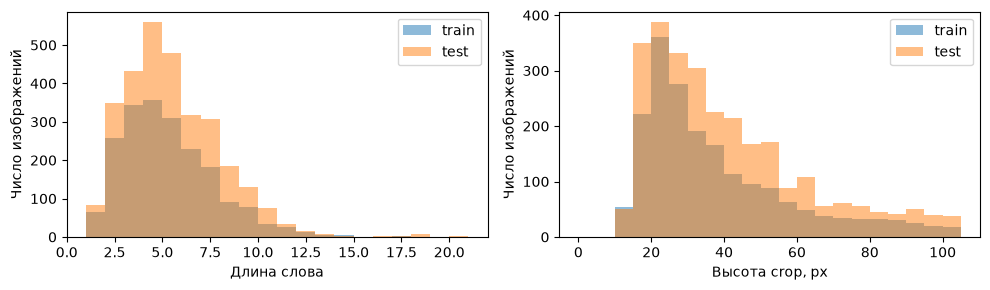

In [4]:
meta = {}
for split in ('train', 'test'):
    meta[split] = pd.read_csv(DATA / f'{split}data.csv')[['ImgName', 'GroundTruth']]
    expected = {f'{split}/{path.name}' for path in real[split]}
    observed = set(meta[split].ImgName)
    assert expected == observed, f'Метаданные и файлы {split} не совпадают'

study = []
heights_by_split = {}
for split in ('train', 'test'):
    widths, heights = [], []
    for path in real[split]:
        with Image.open(path) as im:
            widths.append(im.width)
            heights.append(im.height)
    heights_by_split[split] = heights
    words = meta[split].GroundTruth.fillna('').astype(str)
    study.append({'split': split, 'изображений': len(real[split]),
                  'медианная ширина': np.median(widths),
                  'медианная высота': np.median(heights),
                  'высота < 16 px': np.mean(np.array(heights) < 16),
                  'длина слова ≤ 3': np.mean(words.str.len() <= 3),
                  'число групп': len({path.stem.split('_')[0] for path in real[split]})})
study = pd.DataFrame(study)
display(study.round(3))
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for split in ('train', 'test'):
    lengths = meta[split].GroundTruth.fillna('').astype(str).str.len()
    axes[0].hist(lengths, bins=np.arange(1, 22), alpha=.5, label=split)
    axes[1].hist(heights_by_split[split], bins=np.arange(0, 110, 5), alpha=.5, label=split)
axes[0].set(xlabel='Длина слова', ylabel='Число изображений')
axes[1].set(xlabel='Высота crop, px', ylabel='Число изображений')
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

## 3. Признаки реальных слов

Исходному слову ставим метку `0`, его повороту на 180° метку `1`. Иногда исходная ориентация может быть нестандартной.

In [5]:
real_cache = ART / 'iiit5k_geometry_features.joblib'
signature = [(split, str(path), path.stat().st_size, path.stat().st_mtime_ns)
             for split in ('train', 'test') for path in real[split]]
if real_cache.exists():
    payload = joblib.load(real_cache)
else:
    payload = {}
if payload.get('signature') != signature:
    started = time.perf_counter()
    features = {}
    valid_paths = {}
    for split in ('train', 'test'):
        vectors, paths = [], []
        for path in real[split]:
            try:
                with Image.open(path) as im:
                    vectors.append(orientation_features(im))
                paths.append(path)
            except (OSError, ValueError):
                pass
        features[split] = np.stack(vectors)
        valid_paths[split] = paths
    payload = {'signature': signature, 'features': features, 'paths': valid_paths}
    joblib.dump(payload, real_cache)
    print('Извлечение признаков, секунд', round(time.perf_counter() - started, 1))
real_features = payload['features']
real_paths = payload['paths']
print({split: real_features[split].shape for split in real_features})
print('Пропущено повреждённых файлов', {s: len(real[s]) - len(real_paths[s]) for s in real})

{'train': (2000, 6), 'test': (3000, 6)}
Пропущено повреждённых файлов {'train': 0, 'test': 0}


Проверяем, меняет ли поворот знак признаков.

In [6]:
sample_ids = rng.choice(len(real_paths['train']), size=min(50, len(real_paths['train'])), replace=False)
rotation_errors = []
for i in sample_ids:
    with Image.open(real_paths['train'][i]) as im:
        f = orientation_features(im)
        fr = orientation_features(im.transpose(Image.Transpose.ROTATE_180))
    rotation_errors.append(np.abs(f + fr).mean())
print('Средняя ошибка смены знака', round(float(np.mean(rotation_errors)), 5))

Средняя ошибка смены знака 0.0


Сравниваем признаки синтетики и IIIT5K. Так виден переход к реальным изображениям.

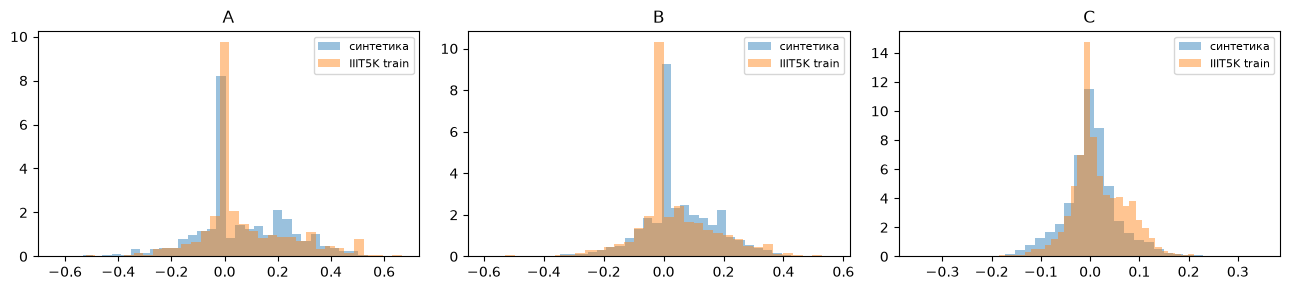

Доля пустых признаков, синтетика 0.029
Доля пустых признаков, IIIT5K train 0.084


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3))
syn_probe = synthetic if 'synthetic' in globals() else np.load(ART / 'article_features_10000_42_43e1b9991a.npz')['features']
for ax, j, label in zip(axes, range(3), ['A', 'B', 'C']):
    ax.hist(syn_probe[:, j], bins=35, density=True, alpha=.45, label='синтетика')
    ax.hist(real_features['train'][:, j], bins=35, density=True, alpha=.45, label='IIIT5K train')
    ax.set_title(label)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
print('Доля пустых признаков, синтетика', round(np.mean(np.all(syn_probe == 0, axis=1)), 3))
print('Доля пустых признаков, IIIT5K train', round(np.mean(np.all(real_features['train'] == 0, axis=1)), 3))

Берём 2 000 боксов Avito без меток. Сравниваем модули признаков, поскольку ориентация этих боксов неизвестна.

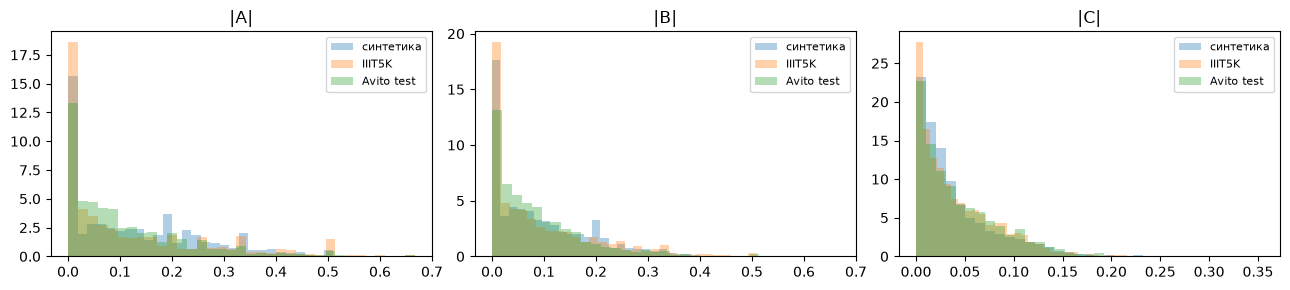

Доля пустых признаков в Avito test 0.066


In [8]:
avito_ids = pd.read_csv(ROOT / 'sample_submission.csv', dtype={'image_id': str}).image_id
avito_ids = avito_ids.sample(n=min(2000, len(avito_ids)), random_state=SEED)
avito_vectors = []
for image_id in avito_ids:
    with Image.open(ROOT / 'test' / 'images' / f'{image_id}.png') as im:
        avito_vectors.append(orientation_features(im))
avito_vectors = np.stack(avito_vectors)
fig, axes = plt.subplots(1, 3, figsize=(13, 3))
for ax, j, label in zip(axes, range(3), ['|A|', '|B|', '|C|']):
    for name, x in [('синтетика', syn_probe), ('IIIT5K', real_features['train']), ('Avito test', avito_vectors)]:
        ax.hist(np.abs(x[:, j]), bins=35, density=True, alpha=.35, label=name)
    ax.set_title(label)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
print('Доля пустых признаков в Avito test', round(np.mean(np.all(avito_vectors == 0, axis=1)), 3))

## 4. Разделение данных

Восстанавливаем разделение синтетики из `research.ipynb`. Реальные слова делим по группе изображений до создания повёрнутых пар.

In [9]:
synthetic_path = ART / 'article_features_10000_42_43e1b9991a.npz'
if not synthetic_path.exists():
    raise FileNotFoundError(f'Сначала выполните research.ipynb. Нет файла {synthetic_path}')
synthetic = np.load(synthetic_path)['features']
assert synthetic.shape == (10000, 6)
base_ids = np.arange(len(synthetic))
syn_traincal, syn_val = next(GroupShuffleSplit(n_splits=1, test_size=.2, random_state=SEED).split(base_ids, groups=base_ids))
syn_train_pos, syn_cal_pos = next(GroupShuffleSplit(n_splits=1, test_size=.2, random_state=SEED + 1).split(syn_traincal, groups=syn_traincal))
syn_train, syn_cal = syn_traincal[syn_train_pos], syn_traincal[syn_cal_pos]
real_ids = np.arange(len(real_paths['train']))
scene_groups = np.array([path.stem.split('_')[0] for path in real_paths['train']])
real_train, real_cal = next(GroupShuffleSplit(n_splits=1, test_size=.2, random_state=SEED).split(real_ids, groups=scene_groups))
assert not set(scene_groups[real_train]) & set(scene_groups[real_cal])
print('Синтетика train/cal/val', len(syn_train), len(syn_cal), len(syn_val))
print('IIIT5K train/cal/test', len(real_train), len(real_cal), len(real_paths['test']))

Синтетика train/cal/val 6400 1600 2000
IIIT5K train/cal/test 1602 398 3000


In [10]:
def make_pairs(base):
    base = np.asarray(base)
    return (np.concatenate([base, -base]),
            np.r_[np.zeros(len(base), dtype=int), np.ones(len(base), dtype=int)])

X_syn_train, y_syn_train = make_pairs(synthetic[syn_train])
X_syn_val, y_syn_val = make_pairs(synthetic[syn_val])
X_real_train, y_real_train = make_pairs(real_features['train'][real_train])
X_real_cal, y_real_cal = make_pairs(real_features['train'][real_cal])
X_real_test, y_real_test = make_pairs(real_features['test'])
assert not set(real_train) & set(real_cal)
assert X_real_test.shape[0] == 2 * len(real_paths['test'])

## 5. Обучение

Сравниваем синтетику со смесью синтетики и IIIT5K. В смеси оба источника получают одинаковый общий вес. Температуру настраиваем на отдельной части реального `train`.

Свободного члена нет, поэтому $p(R_{180}x)pprox1-p(x)$.

In [11]:
def train_model(X, y, weights=None):
    model = LogisticRegression(fit_intercept=False, C=1, max_iter=1000, random_state=SEED)
    model.fit(X, y, sample_weight=weights)
    return model

def calibrate(model, X, y):
    logits = model.decision_function(X)
    loss = lambda log_t: brier_score_loss(y, expit(logits / np.exp(log_t)))
    result = minimize_scalar(loss, bounds=(-3, 4), method='bounded')
    return float(np.exp(result.x))

def predict(model, temperature, X):
    return expit(model.decision_function(X) / temperature)

started = time.perf_counter()
syn_model = train_model(X_syn_train, y_syn_train)
X_mixed = np.concatenate([X_syn_train, X_real_train])
y_mixed = np.concatenate([y_syn_train, y_real_train])
weights = np.r_[np.full(len(y_syn_train), .5 / len(y_syn_train)),
                np.full(len(y_real_train), .5 / len(y_real_train))] * len(y_mixed)
mixed_model = train_model(X_mixed, y_mixed, weights)
train_seconds = time.perf_counter() - started
syn_temperature = calibrate(syn_model, X_real_cal, y_real_cal)
mixed_temperature = calibrate(mixed_model, X_real_cal, y_real_cal)
models = {'synthetic only': (syn_model, syn_temperature),
          'synthetic + IIIT5K': (mixed_model, mixed_temperature)}
print('Обучение, секунд', round(train_seconds, 3))
for name, (model, temperature) in models.items():
    print(name, 'T', round(temperature, 3), 'коэффициенты', np.round(model.coef_, 3))

Обучение, секунд 0.028
synthetic only T 1.09 коэффициенты [[ 0.98  -0.842  1.711 -6.153 -6.161  7.901]]
synthetic + IIIT5K T 0.933 коэффициенты [[-2.003  0.771 -2.022 -3.851 -3.487  4.953]]


## 6. Качество на IIIT5K

Считаем метрики на исходном `test`. Он не участвовал в обучении и калибровке.

In [12]:
def measure(name, y, p, domain):
    brier = brier_score_loss(y, p)
    return {'данные': domain, 'модель': name,
            'accuracy': accuracy_score(y, p >= .5),
            'ROC-AUC': roc_auc_score(y, p),
            'Brier': brier, '1-Brier': 1 - brier}

rows = []
for domain, X, y in [('IIIT5K test', X_real_test, y_real_test),
                     ('synthetic validation', X_syn_val, y_syn_val)]:
    rows.append(measure('constant 0.5', y, np.full(len(y), .5), domain))
    for name, (model, temperature) in models.items():
        rows.append(measure(name, y, predict(model, temperature, X), domain))
results = pd.DataFrame(rows)
display(results.round(4))
results.to_csv(ART / 'iiit5k_geometry_results.csv', index=False)

,данные,модель,accuracy,ROC-AUC,Brier,1-Brier
0,IIIT5K test,constant 0.5,0.5000,0.5000,0.2500,0.7500
1,IIIT5K test,synthetic only,0.5903,0.6342,0.2378,0.7622
2,IIIT5K test,synthetic + IIIT5K,0.6133,0.6834,0.2196,0.7804
3,synthetic validation,constant 0.5,0.5000,0.5000,0.2500,0.7500
4,synthetic validation,synthetic only,0.6660,0.7383,0.2068,0.7932
5,synthetic validation,synthetic + IIIT5K,0.6555,0.7101,0.2166,0.7834


## 7. Калибровка

Смотрим, насколько вероятности соответствуют доле перевёрнутых слов. Проверяем сумму вероятностей у повёрнутой пары.

synthetic only максимальная ошибка парности 1.1920929e-07
synthetic + IIIT5K максимальная ошибка парности 1.1920929e-07


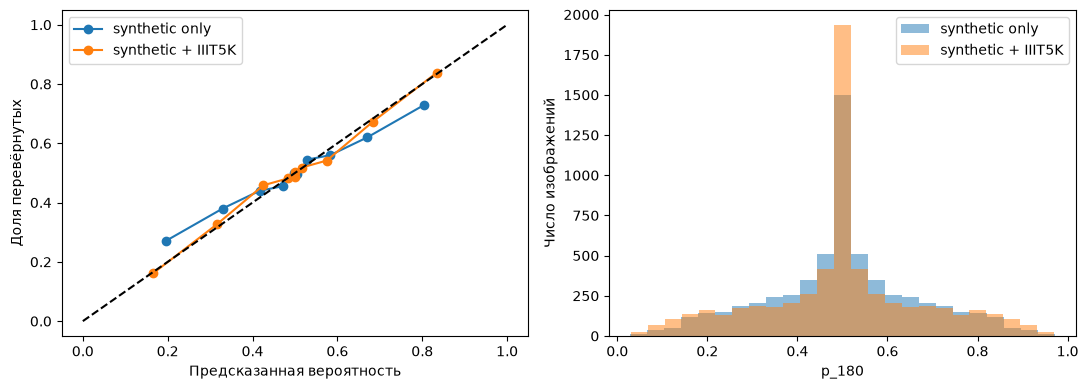

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name, (model, temperature) in models.items():
    p = predict(model, temperature, X_real_test)
    frac, mean = calibration_curve(y_real_test, p, n_bins=10, strategy='quantile')
    axes[0].plot(mean, frac, 'o-', label=name)
    axes[1].hist(p, bins=25, alpha=.5, label=name)
    n = len(real_paths['test'])
    print(name, 'максимальная ошибка парности', np.max(np.abs(p[:n] + p[n:] - 1)))
axes[0].plot([0, 1], [0, 1], 'k--')
axes[0].set(xlabel='Предсказанная вероятность', ylabel='Доля перевёрнутых')
axes[1].set(xlabel='p_180', ylabel='Число изображений')
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

## 8. Примеры предсказаний

Рядом стоят исходное слово и его поворот. Подпись показывает $p_{180}$ смешанной модели.

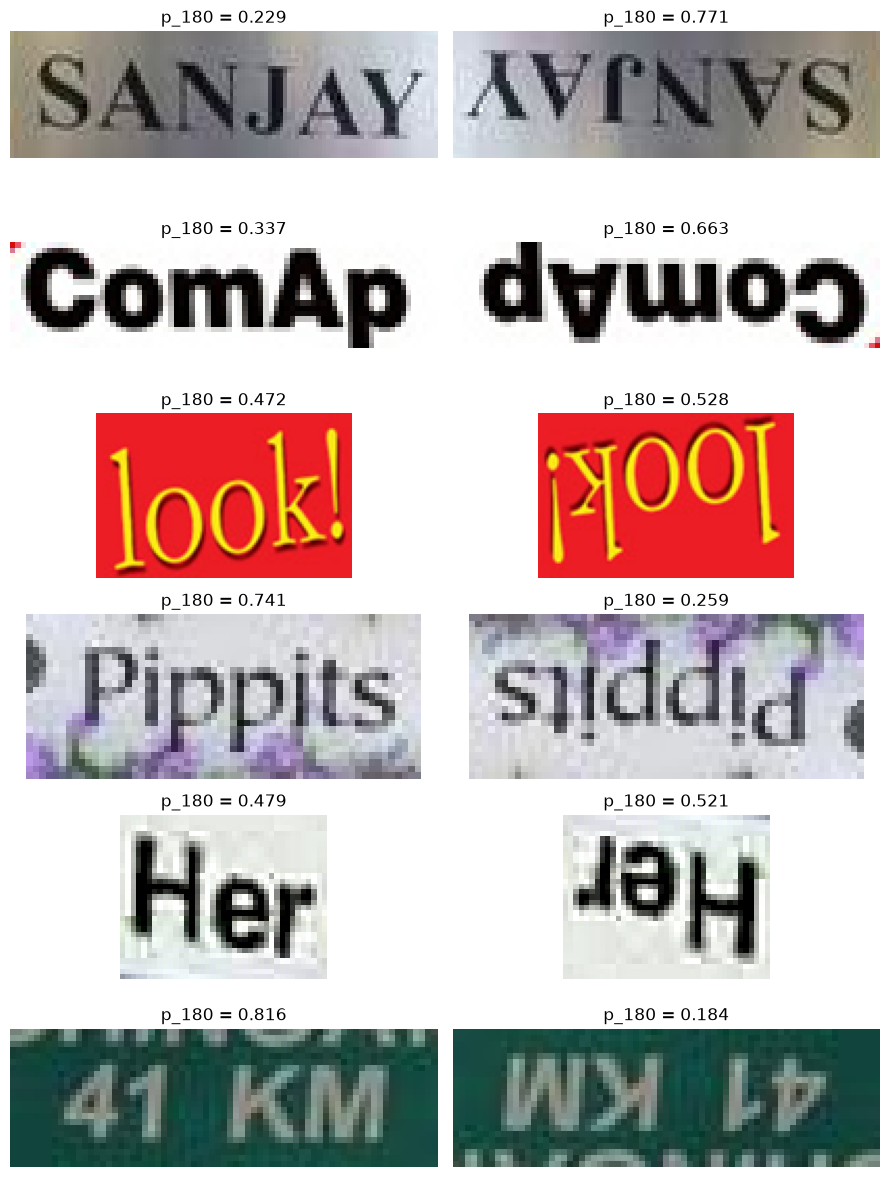

In [14]:
p_real = predict(mixed_model, mixed_temperature, X_real_test)
n = len(real_paths['test'])
chosen = rng.choice(n, size=min(6, n), replace=False)
fig, axes = plt.subplots(len(chosen), 2, figsize=(9, 2 * len(chosen)))
axes = np.atleast_2d(axes)
for row, i in enumerate(chosen):
    with Image.open(real_paths['test'][i]) as im:
        upright = im.convert('RGB')
    for col, image, p in [(0, upright, p_real[i]),
                          (1, upright.transpose(Image.Transpose.ROTATE_180), p_real[n + i])]:
        axes[row, col].imshow(image)
        axes[row, col].set_title(f'p_180 = {p:.3f}')
        axes[row, col].axis('off')
plt.tight_layout()
plt.show()

## 9. Ошибки

Показываем уверенные ошибки и случаи около 0,5. Отдельно проверяем короткие слова и изображения без найденных компонент.

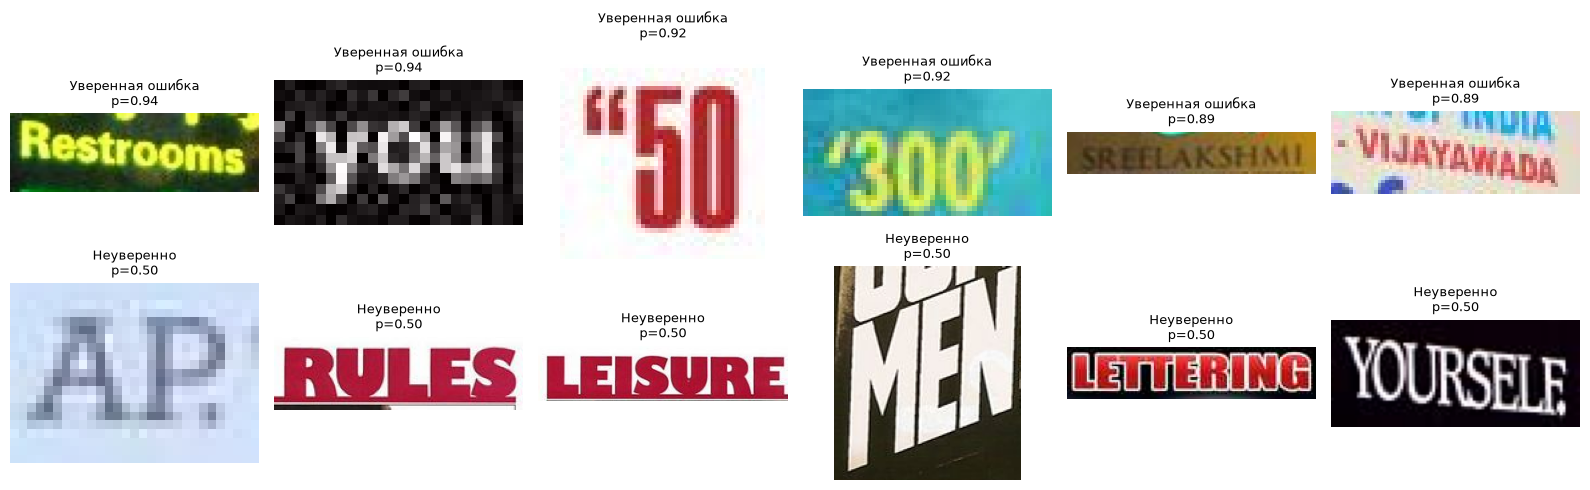

,size,accuracy
short,,
False,2134,0.626992
True,866,0.579677


,size,accuracy
few_components,,
False,2624,0.629573
True,376,0.500000


Нулевые признаки в test 376 из 3000


In [15]:
p0 = p_real[:n]
confidence = np.abs(p0 - .5)
wrong = np.flatnonzero(p0 > .5)
uncertain = np.argsort(confidence)[:6]
confident_wrong = wrong[np.argsort(-confidence[wrong])[:6]]
fig, axes = plt.subplots(2, 6, figsize=(16, 5))
for row, indices, title in [(0, confident_wrong, 'Уверенная ошибка'),
                             (1, uncertain, 'Неуверенно')]:
    for col, ax in enumerate(axes[row]):
        if col < len(indices):
            i = int(indices[col])
            with Image.open(real_paths['test'][i]) as im:
                ax.imshow(im)
            ax.set_title(f'{title}\np={p0[i]:.2f}', fontsize=9)
        ax.axis('off')
plt.tight_layout()
plt.show()
word_by_name = meta['test'].set_index('ImgName').GroundTruth
real_words = np.array([word_by_name[f'test/{path.name}'] for path in real_paths['test']])
pair_accuracy = np.where(p0 == .5, .5, (p0 < .5).astype(float))
error_frame = pd.DataFrame({'word': real_words, 'pair_accuracy': pair_accuracy,
                            'short': np.array([len(str(w)) <= 3 for w in real_words]),
                            'few_components': np.sum(real_features['test'] != 0, axis=1) == 0})
display(error_frame.groupby('short').pair_accuracy.agg(['size', 'mean']).rename(columns={'mean': 'accuracy'}))
display(error_frame.groupby('few_components').pair_accuracy.agg(['size', 'mean']).rename(columns={'mean': 'accuracy'}))
print('Нулевые признаки в test', int(error_frame.few_components.sum()), 'из', len(error_frame))

## 10. Скорость и модель

Измеряем время от открытия файла до вероятности. Сохраняем веса, температуру и названия признаков.

In [16]:
bench_paths = real_paths['test'][:min(300, len(real_paths['test']))]
started = time.perf_counter()
bench = []
for path in bench_paths:
    with Image.open(path) as im:
        bench.append(orientation_features(im))
bench = np.stack(bench)
_ = predict(mixed_model, mixed_temperature, bench)
ms_per_image = 1000 * (time.perf_counter() - started) / len(bench_paths)
model_bundle = {'model': mixed_model, 'temperature': mixed_temperature,
                'feature_names': ['A', 'B', 'C', 'A_reliability', 'B_reliability', 'C_reliability'],
                'source': 'research.ipynb, geometry full',
                'training_data': 'synthetic + IIIT5K train'}
model_path = ART / 'geometry_mixed_iiit5k.joblib'
joblib.dump(model_bundle, model_path)
print('мс на изображение', round(ms_per_image, 3))
print('изображений в секунду', round(1000 / ms_per_image, 1))
print('признаков', bench.shape[1])
print('размер модели, КБ', round(model_path.stat().st_size / 1024, 1))
print('модель', model_path)

мс на изображение 0.614
изображений в секунду 1629.5
признаков 6
размер модели, КБ 1.1
модель /home/nick-pc/Programming/avito-task/artifacts/geometry_mixed_iiit5k.joblib


## 11. Submission смешанной модели

Считаем вероятность для всех боксов Avito. Порядок и названия столбцов берём из `sample_submission.csv`. Метки test не используются.

In [17]:
sample = pd.read_csv(ROOT / 'sample_submission.csv', dtype={'image_id': str})
assert sample.columns.tolist() == ['image_id', 'p_180']
assert sample.image_id.is_unique
probabilities = []
for start in range(0, len(sample), 256):
    batch = []
    for image_id in sample.image_id.iloc[start:start + 256]:
        with Image.open(ROOT / 'test' / 'images' / f'{image_id}.png') as im:
            batch.append(orientation_features(im))
    probabilities.extend(predict(mixed_model, mixed_temperature, np.stack(batch)))
submission = sample[['image_id']].copy()
submission['p_180'] = np.asarray(probabilities, dtype=np.float64)
assert len(submission) == len(sample)
assert submission.image_id.equals(sample.image_id)
assert np.isfinite(submission.p_180).all()
assert submission.p_180.between(0, 1).all()
submission_path = ROOT / 'submission_iiit5k.csv'
submission.to_csv(submission_path, index=False)
display(submission.head())
print('Сохранён', submission_path)
print('Квантили p_180', submission.p_180.quantile([0, .1, .5, .9, 1]).round(3).to_dict())

,image_id,p_180
0,test_00000,0.500000
1,test_00001,0.418163
2,test_00002,0.501555
3,test_00003,0.418832
4,test_00004,0.573778


Сохранён /home/nick-pc/Programming/avito-task/submission_iiit5k.csv
Квантили p_180 {0.0: 0.011, 0.1: 0.263, 0.5: 0.5, 0.9: 0.736, 1.0: 0.988}


Готов `submission_iiit5k.csv`. Это предсказания модели, обученной на синтетике и IIIT5K.

## Выводы

На IIIT5K смесь подняла `1-Brier` с 0,7622 до 0,7804. На синтетической validation результат снизился с 0,7932 до 0,7834.

У 376 из 3 000 реальных crop признаки равны нулю. Модель выдаёт для них 0,5. Часто мешают короткие слова, цифры и крупные прописные буквы.

Графики Avito показывают разницу изображений без знания меток. Качество на Avito пока неизвестно.